# One strategy across four futures of one market

This notebook runs `fork_futures.py`, the script beside it, and shows what it measures. The script is the source of
truth: every number and the figure below come from its `run`, `table` and `svg` functions.

One seeded market runs for 40 days with a buy-and-hold portfolio in it. The world is then forked into four
branches. Three of them get a packaged scenario on the first day after the fork (`rate_shock`, `recession`,
`liquidity_crisis`), and the control gets none. All four run for 80 more days.

In [1]:
import fork_futures as study

result = study.run()
print(f"tradefloor {result['version']}, preset {result['preset']}, seed {result['seed']}")
for name in study.SCENARIOS:
    print(f"{name:<18} identical to control at the fork: {result['identical_at_fork'][name]}")

tradefloor 0.11.0, preset pt-v22, seed 7
rate_shock         identical to control at the fork: True
recession          identical to control at the fork: True
liquidity_crisis   identical to control at the fork: True


`tf.agree` checks each branch against the control at the fork, before any scenario is applied. A `True` on every
line means the four branches share the first 40 days to the bit, so the gap between two curves after the fork is
the scenario and nothing else.

In [2]:
print(study.table(result))
at_fork = result["shared"][-1]
print()
for name in study.BRANCHES:
    final = result["branches"][name][-1]
    print(f"{name:<18} {(final / at_fork - 1.0) * 100.0:+.2f}% since the fork")

   day           control        rate_shock         recession  liquidity_crisis
     0            100.00            100.00            100.00            100.00
    10            101.15            101.15            101.15            101.15
    20            100.35            100.35            100.35            100.35
    30            103.71            103.71            103.71            103.71
    40            104.50            104.50            104.50            104.50
    50            103.53             95.86             75.40             78.47
    60            104.66             97.58             80.20             84.47
    70            106.70             98.83             82.37             86.55
    80            105.07             97.77             69.41             77.27
    90            106.71             99.44             72.75             80.32
   100            106.40             99.86             72.01             80.71
   110            108.00            100.85          

The table is the portfolio's value with the starting capital as 100. The same series drawn as the figure the
project README shows:

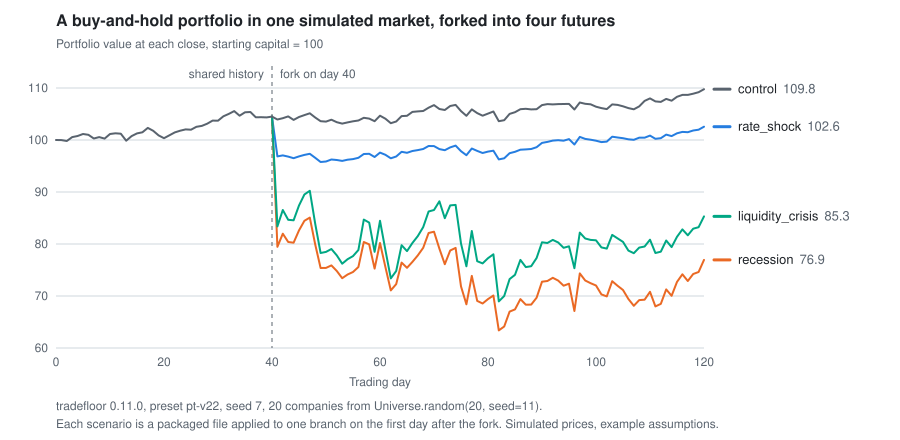

In [3]:
from IPython.display import SVG, display

display(SVG(study.svg(result, "light")))

The scenarios are example assumptions that ship with the library, not forecasts. `tradefloor scenario show
recession` prints what each one changes and when.